# Tutorial 4: Linear elasticity in 3D

Vector problems have $m>1$ components. We compute the displacement $u=(u_x,u_y,u_z)$ of an elastic
block $[0,4]\times[0,1]\times[0,1]$ with Young's modulus $E=1$ and Poisson ratio $\nu=0.3$, clamped at
$x=0$ and loaded by a uniform downward traction $q$ on $x=4$. On the face $y=0$, we impose a
**symmetry condition**, which constrains only one component ($u_y=0$), to show that Dirichlet
conditions can be set component by component. The remaining faces are traction free.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seemps.analysis.mesh import ChebyshevInterval, Mesh
from seemps.state import MPS

from seemps_galerkin import (
    BoundaryFace,
    BoundaryProblem,
    BulkProblem,
    DirichletBoundaryCondition,
    RobinBoundaryCondition,
    TensorField,
)
from seemps_galerkin.mps.factories import mps_identity, mps_zeros
from seemps_galerkin.mps.factories.transform import mpo_chebyshev_transform
from seemps_galerkin.solve import solve_mps_bvp

E, ν, q = 1.0, 0.3, 1e-5
λ = E * ν / ((1 + ν) * (1 - 2 * ν))
μ_lame = E / (2 * (1 + ν))

sites = (4, 3, 3)  # 16 × 8 × 8 nodes
mesh = Mesh(
    [ChebyshevInterval(0.0, length, 2**s, endpoints=False) for length, s in zip((4.0, 1.0, 1.0), sites)]
)
d = m = 3
n = sum(sites)

## 1. Elasticity tensor

For an isotropic material, $C_{\mu\alpha\nu\beta}=\lambda\,\delta_{\alpha\mu}\delta_{\beta\nu}+
\mu\,(\delta_{\alpha\beta}\delta_{\mu\nu}+\delta_{\alpha\nu}\delta_{\beta\mu})$. Only its nonzero
entries are set; a heterogeneous material would use a variable field in place of `mps_identity`.

In [2]:
principal = TensorField[MPS]((d, d, m, m), mesh.dimensions)
for α in range(d):
    for β in range(d):
        for μ in range(m):
            for ν_ in range(m):
                c = λ * (α == μ) * (β == ν_) + μ_lame * ((α == β) * (μ == ν_) + (α == ν_) * (β == μ))
                if c:
                    principal[α, β, μ, ν_] = c * mps_identity(n)
bulk = BulkProblem(mesh, principal, TensorField[MPS]((m, m), mesh.dimensions), TensorField[MPS]((m,), mesh.dimensions))

## 2. Boundary conditions, component by component

The data of a condition are a `TensorField` with one entry per component:

- in a **Dirichlet** condition, a component with data is constrained, and an empty (`None`)
  component is left free, with zero traction;
- in a **Robin** condition, the data are the traction, $(C\nabla u)\cdot n = g$ here, and empty
  components have zero traction.

In [3]:
def face_shape(dim):
    return mesh.dimensions[:dim] + mesh.dimensions[dim + 1 :]


def face_sites(dim):
    return sum(sites) - sites[dim]


conditions = []

# x = 0: clamped, all components fixed
data = TensorField[MPS]((m,), face_shape(0))
for component in range(m):
    data[component] = mps_zeros(face_sites(0))
conditions.append(DirichletBoundaryCondition(BoundaryFace(0, is_left=True), data))

# x = 4: downward traction on u_z
data = TensorField[MPS]((m,), face_shape(0))
data[2] = -q * mps_identity(face_sites(0))
conditions.append(RobinBoundaryCondition(BoundaryFace(0, is_left=False), TensorField[MPS]((m, m), face_shape(0)), data))

# y = 0: symmetry plane, only u_y = 0
data = TensorField[MPS]((m,), face_shape(1))
data[1] = mps_zeros(face_sites(1))
conditions.append(DirichletBoundaryCondition(BoundaryFace(1, is_left=True), data))

# Remaining faces: traction free
for dim, is_left in ((1, False), (2, True), (2, False)):
    conditions.append(
        RobinBoundaryCondition(
            BoundaryFace(dim, is_left), TensorField[MPS]((m, m), face_shape(dim)), TensorField[MPS]((m,), face_shape(dim))
        )
    )
boundary = BoundaryProblem(mesh, conditions)

## 3. Solve and read the components

For $m>1$, the solution MPS has a first site of dimension $m$ that selects the component,
followed by the sites of each coordinate. To get nodal values, we apply the inverse Chebyshev
transform to the sites of each coordinate, extended to act as the identity elsewhere.

In [4]:
ψ = solve_mps_bvp(bulk, boundary)
print(f"solution: {ψ.size} sites, physical dimensions {ψ.physical_dimensions()[:4]}..., bond dimension {ψ.max_bond_dimension()}")

start = 1
for s in sites:
    # `extend` takes the physical dimensions of the sites it does not act on.
    transform = mpo_chebyshev_transform(s, inverse=True).extend(
        n + 1, sites=list(range(start, start + s)), dimensions=[m] + [2] * (n - s)
    )
    ψ = transform.apply(ψ)
    start += s
u = ψ.to_vector().reshape(m, *mesh.dimensions)

solution: 11 sites, physical dimensions [3, 2, 2, 2]..., bond dimension 45


## 4. Results

The deflection along the beam axis is close to the Euler–Bernoulli prediction
$w(x)=\frac{P}{6EI}x^2(3L-x)$ with $P=q\,b\,h$ and $I=bh^3/12$, which neglects shear deformation and
therefore slightly underestimates it for this short beam.

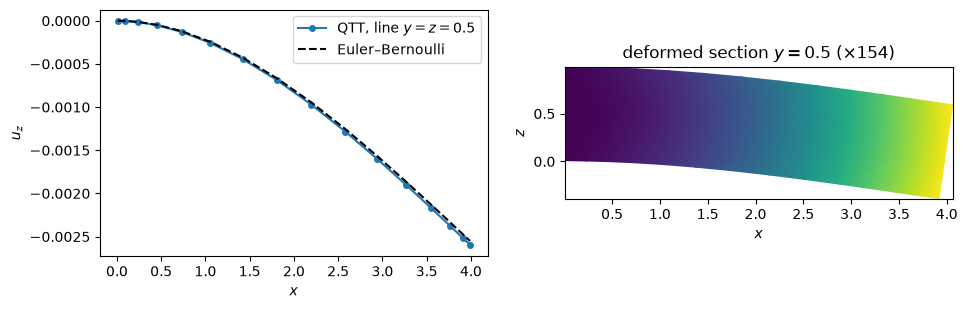

tip deflection: QTT -2.5943e-03, Euler–Bernoulli -2.5508e-03


In [5]:
x, y, z = (interval.to_vector() for interval in mesh.intervals)
j, k = np.argmin(np.abs(y - 0.5)), np.argmin(np.abs(z - 0.5))
L, b, h = 4.0, 1.0, 1.0
P, I = q * b * h, b * h**3 / 12
beam = -P / (6 * E * I) * x**2 * (3 * L - x)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
axs[0].plot(x, u[2, :, j, k], "o-", ms=4, label="QTT, line $y=z=0.5$")
axs[0].plot(x, beam, "k--", label="Euler–Bernoulli")
axs[0].set_xlabel("$x$")
axs[0].set_ylabel("$u_z$")
axs[0].legend()

scale = 0.4 / np.max(np.abs(u))
X, Z = np.meshgrid(x, z, indexing="ij")
axs[1].pcolormesh(X + scale * u[0, :, j, :], Z + scale * u[2, :, j, :], np.linalg.norm(u[:, :, j, :], axis=0), shading="gouraud")
axs[1].set_aspect("equal")
axs[1].set_title(f"deformed section $y=0.5$ (×{scale:.0f})")
axs[1].set_xlabel("$x$")
axs[1].set_ylabel("$z$")
plt.show()
print(f"tip deflection: QTT {u[2, -1, j, k]:.4e}, Euler–Bernoulli {beam[-1]:.4e}")

## Summary

- Vector problems set `principal`, `reaction` and `source` with $m>1$ components.
- Dirichlet data are set component by component; empty components are free.
- Traction loads are Robin data, and traction-free faces are Robin conditions with empty fields.
- The solution has a leading component site; transform each coordinate back to read nodal values.